# Visualisations Customer Churn

Objectif : generer des visualisations analytiques propres pour le rapport ou la plateforme.

Les images sont sauvegardees dans : `visualisation/figures/`.

Ce notebook contient deux familles de visuels :
- analyse descriptive de la base
- analyse du churn selon plusieurs variables

In [16]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import numpy as np

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "visualisation" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Figures directory:", OUTPUT_DIR)

Project root: c:\Users\bourbia\Desktop\projet_pythonn
Figures directory: c:\Users\bourbia\Desktop\projet_pythonn\visualisation\figures


## Style graphique

In [17]:
BG = "#f7efe1"
PANEL = "#fffaf0"
INK = "#17211b"
MUTED = "#687466"
MOSS = "#304c3d"
SAGE = "#9caf88"
CORAL = "#d45d4c"
AMBER = "#d99a3d"
TEAL = "#2f7f7a"
GRID = "#dfd4bf"

mpl.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": PANEL,
    "savefig.facecolor": BG,
    "axes.edgecolor": "#d8cdb9",
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": INK,
    "font.family": "serif",
    "font.serif": ["Georgia", "Times New Roman", "DejaVu Serif"],
    "axes.titleweight": "bold",
    "axes.titlesize": 18,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

CATEGORY_LABELS = {
    "Month-to-month": "Mensuel",
    "One year": "Un an",
    "Two year": "Deux ans",
    "Electronic check": "Electronic check",
    "Mailed check": "Cheque postal",
    "Bank transfer (automatic)": "Virement auto.",
    "Credit card (automatic)": "Carte bancaire auto.",
    "Fiber optic": "Fibre optique",
    "DSL": "DSL",
    "No": "Non",
    "Yes": "Oui",
    "No internet service": "Pas d'internet",
    "No phone service": "Pas de telephone",
    "Female": "Femme",
    "Male": "Homme",
}


def label_category(value):
    return CATEGORY_LABELS.get(str(value), str(value))


def polish(ax, grid_axis="y"):
    ax.grid(True, axis=grid_axis, color=GRID, linewidth=0.9, alpha=0.85)
    ax.grid(False, axis="x" if grid_axis == "y" else "y")
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["left"].set_color("#d8cdb9")
    ax.spines["bottom"].set_color("#d8cdb9")


def save(fig, filename):
    fig.savefig(OUTPUT_DIR / filename, dpi=220, bbox_inches="tight")
    plt.close(fig)

## Chargement des donnees nettoyees

In [18]:
df = pd.read_csv(DATA_DIR / "cleaned_dataset.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnBinary
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


## Analyse descriptive de la base

### 1. Repartition churn / non churn

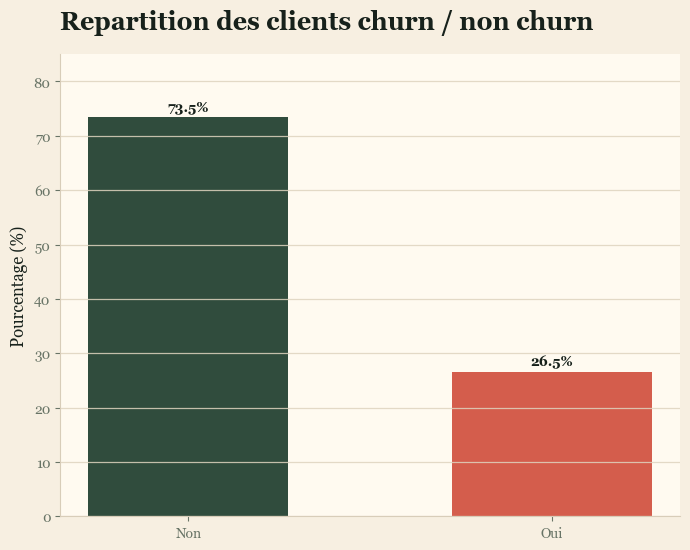

In [19]:
counts = df["Churn"].value_counts()
rates = df["Churn"].value_counts(normalize=True).mul(100).reindex(["No", "Yes"])

fig, ax = plt.subplots(figsize=(8, 6))
colors = [MOSS, CORAL]
bars = ax.bar([label_category(v) for v in rates.index], rates.values, color=colors, width=0.55)
for bar, value in zip(bars, rates.values):
    ax.text(bar.get_x() + bar.get_width()/2, value + 1.2, f"{value:.1f}%", ha="center", fontweight="bold")
ax.set_ylim(0, 85)
ax.set_ylabel("Pourcentage (%)")
ax.set_xlabel("")
ax.set_title("Repartition des clients churn / non churn", loc="left", pad=18)
polish(ax)
plt.show()
save(fig, "base_churn_distribution.png")

### 2. Repartition des types de contrat

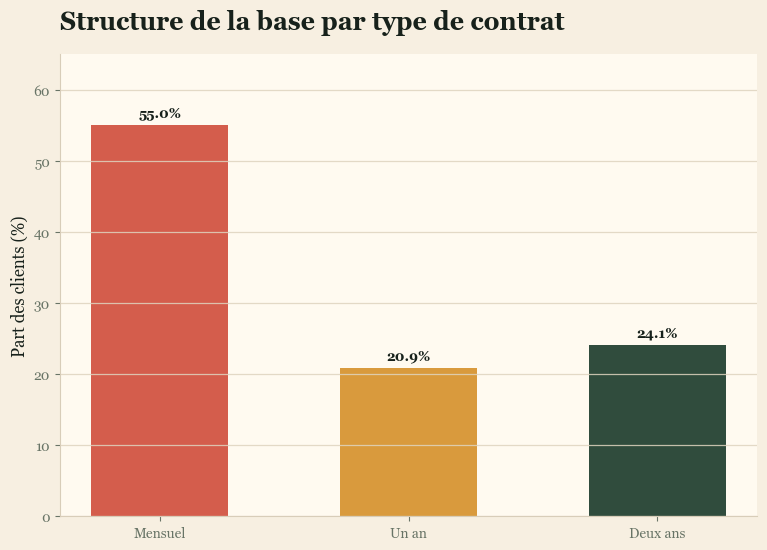

In [20]:
contract_dist = df["Contract"].value_counts(normalize=True).mul(100).reindex(["Month-to-month", "One year", "Two year"])

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar([label_category(v) for v in contract_dist.index], contract_dist.values, color=[CORAL, AMBER, MOSS], width=0.55)
for bar, value in zip(bars, contract_dist.values):
    ax.text(bar.get_x() + bar.get_width()/2, value + 1.2, f"{value:.1f}%", ha="center", fontweight="bold")
ax.set_ylim(0, max(contract_dist.values) + 10)
ax.set_ylabel("Part des clients (%)")
ax.set_xlabel("")
ax.set_title("Structure de la base par type de contrat", loc="left", pad=18)
polish(ax)
plt.show()
save(fig, "base_contract_distribution.png")

### 3. Repartition des services internet

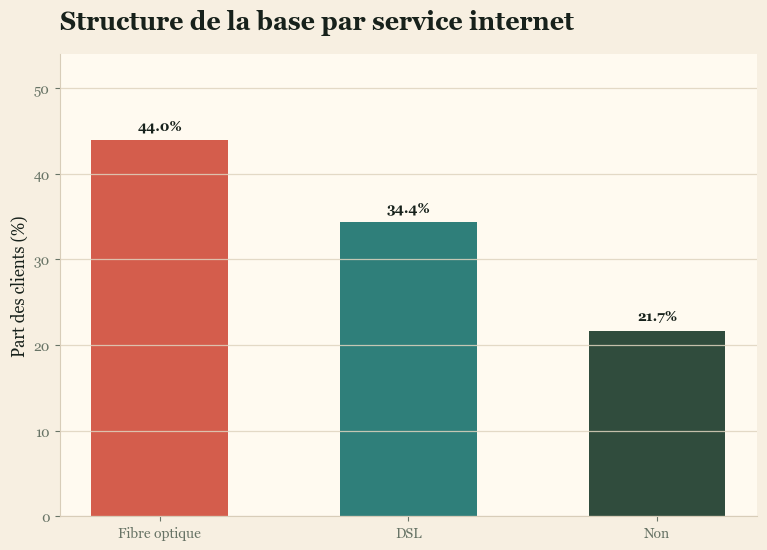

In [21]:
internet_dist = df["InternetService"].value_counts(normalize=True).mul(100).reindex(["Fiber optic", "DSL", "No"])

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar([label_category(v) for v in internet_dist.index], internet_dist.values, color=[CORAL, TEAL, MOSS], width=0.55)
for bar, value in zip(bars, internet_dist.values):
    ax.text(bar.get_x() + bar.get_width()/2, value + 1.2, f"{value:.1f}%", ha="center", fontweight="bold")
ax.set_ylim(0, max(internet_dist.values) + 10)
ax.set_ylabel("Part des clients (%)")
ax.set_xlabel("")
ax.set_title("Structure de la base par service internet", loc="left", pad=18)
polish(ax)
plt.show()
save(fig, "base_internet_distribution.png")

### 4. Distribution de l anciennete

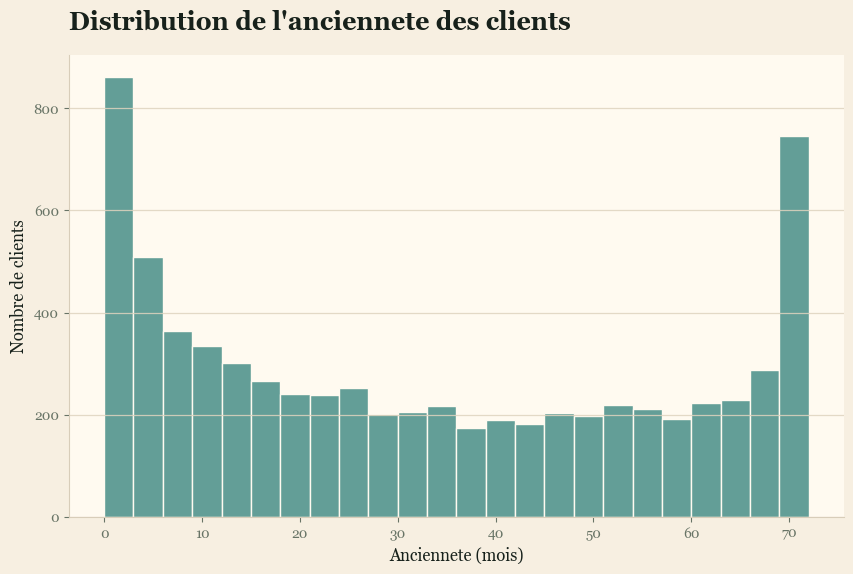

In [22]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(data=df, x="tenure", bins=24, color=TEAL, edgecolor=PANEL, ax=ax)
ax.set_title("Distribution de l'anciennete des clients", loc="left", pad=18)
ax.set_xlabel("Anciennete (mois)")
ax.set_ylabel("Nombre de clients")
polish(ax)
plt.show()
save(fig, "base_tenure_distribution.png")

### 5. Distribution des charges mensuelles

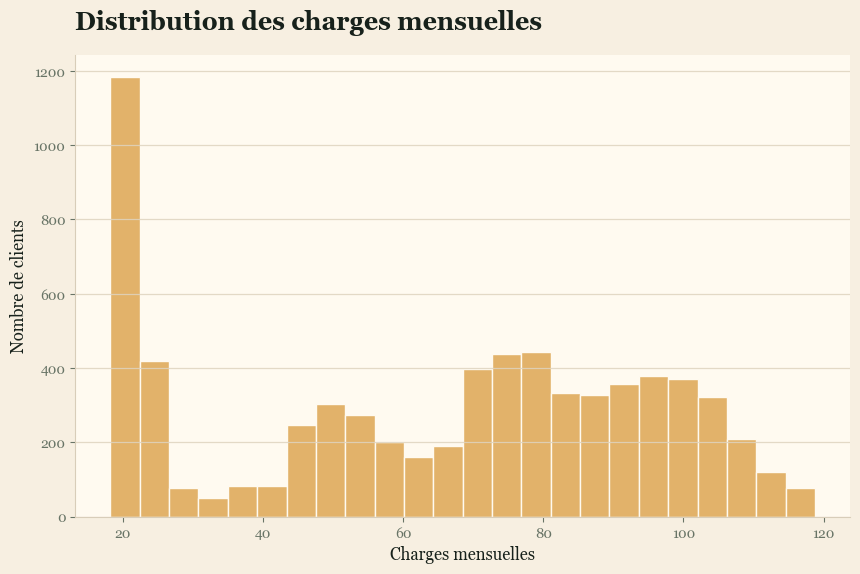

In [23]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(data=df, x="MonthlyCharges", bins=24, color=AMBER, edgecolor=PANEL, ax=ax)
ax.set_title("Distribution des charges mensuelles", loc="left", pad=18)
ax.set_xlabel("Charges mensuelles")
ax.set_ylabel("Nombre de clients")
polish(ax)
plt.show()
save(fig, "base_monthly_charges_distribution.png")

## Analyse du churn selon plusieurs variables

### Churn par type de contrat

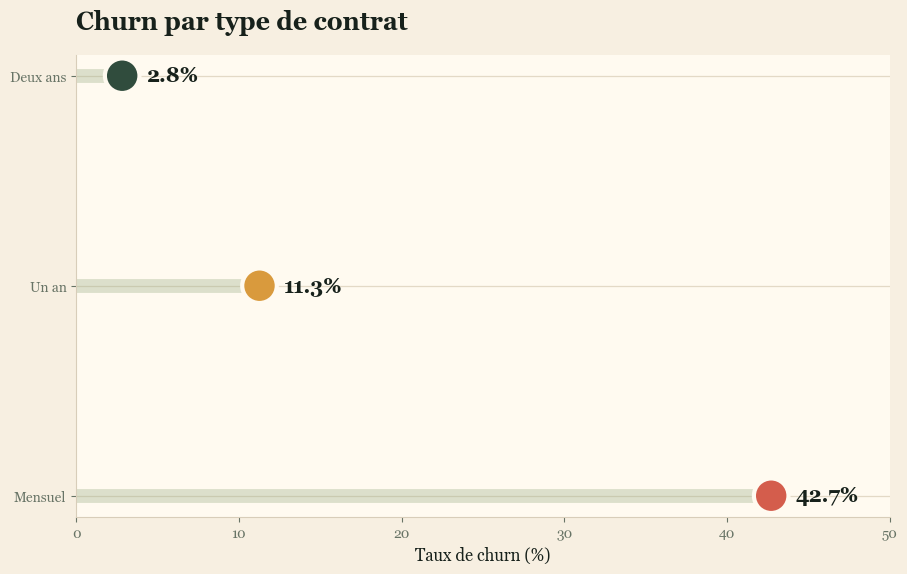

In [24]:
order = ["Month-to-month", "One year", "Two year"]
rates_contract = df.groupby("Contract")["ChurnBinary"].mean().mul(100).reindex(order).reset_index()

fig, ax = plt.subplots(figsize=(10.5, 6.0))
y = np.arange(len(rates_contract))
ax.hlines(y=y, xmin=0, xmax=rates_contract["ChurnBinary"], color=SAGE, linewidth=10, alpha=0.35)
ax.scatter(rates_contract["ChurnBinary"], y, s=620, color=[CORAL, AMBER, MOSS], edgecolor=PANEL, linewidth=3, zorder=3)
for i, value in enumerate(rates_contract["ChurnBinary"]):
    ax.text(value + 1.5, i, f"{value:.1f}%", va="center", fontsize=15, fontweight="bold", color=INK)
ax.set_yticks(y)
ax.set_yticklabels([label_category(v) for v in rates_contract["Contract"]])
ax.set_xlim(0, 50)
ax.set_xlabel("Taux de churn (%)")
ax.set_title("Churn par type de contrat", loc="left", pad=18)
polish(ax)
plt.show()
save(fig, "churn_by_contract.png")

### Churn par methode de paiement

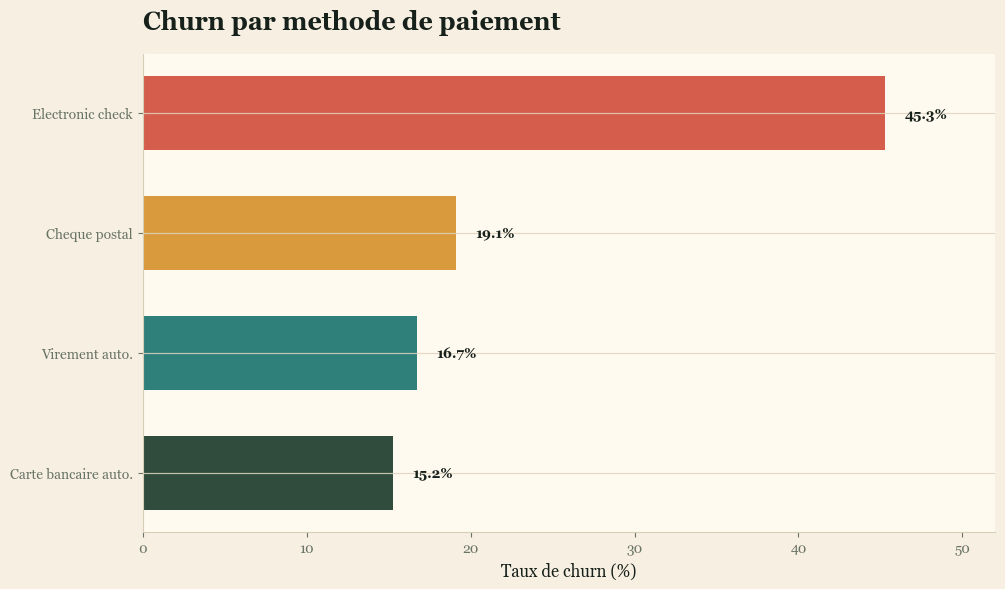

In [25]:
rates_payment = df.groupby("PaymentMethod")["ChurnBinary"].mean().mul(100).sort_values().reset_index()

fig, ax = plt.subplots(figsize=(11, 6.2))
colors = [MOSS, TEAL, AMBER, CORAL]
bars = ax.barh([label_category(v) for v in rates_payment["PaymentMethod"]], rates_payment["ChurnBinary"], color=colors, height=0.62)
for bar, value in zip(bars, rates_payment["ChurnBinary"]):
    ax.text(value + 1.2, bar.get_y() + bar.get_height() / 2, f"{value:.1f}%", va="center", fontweight="bold")
ax.set_xlim(0, 52)
ax.set_xlabel("Taux de churn (%)")
ax.set_ylabel("")
ax.set_title("Churn par methode de paiement", loc="left", pad=18)
polish(ax)
plt.show()
save(fig, "churn_by_payment_method.png")

### Churn par service internet

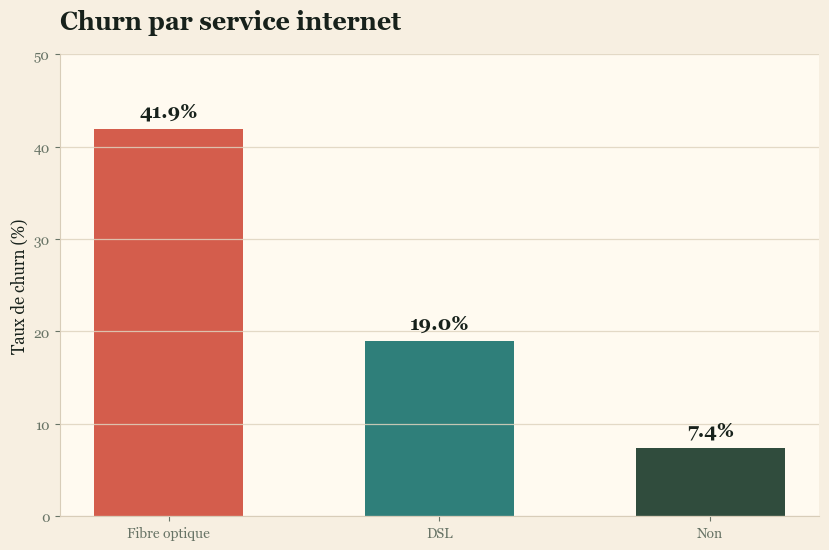

In [26]:
rates_internet = df.groupby("InternetService")["ChurnBinary"].mean().mul(100).sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(9.8, 6.0))
bar_colors = [CORAL if v == rates_internet["ChurnBinary"].max() else (TEAL if label == "DSL" else MOSS) for label, v in zip(rates_internet["InternetService"], rates_internet["ChurnBinary"])]
bars = ax.bar([label_category(v) for v in rates_internet["InternetService"]], rates_internet["ChurnBinary"], color=bar_colors, width=0.55)
for bar, value in zip(bars, rates_internet["ChurnBinary"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1.3, f"{value:.1f}%", ha="center", fontweight="bold", fontsize=14)
ax.set_ylim(0, 50)
ax.set_xlabel("")
ax.set_ylabel("Taux de churn (%)")
ax.set_title("Churn par service internet", loc="left", pad=18)
polish(ax)
plt.show()
save(fig, "churn_by_internet_service.png")

### Churn selon le support technique

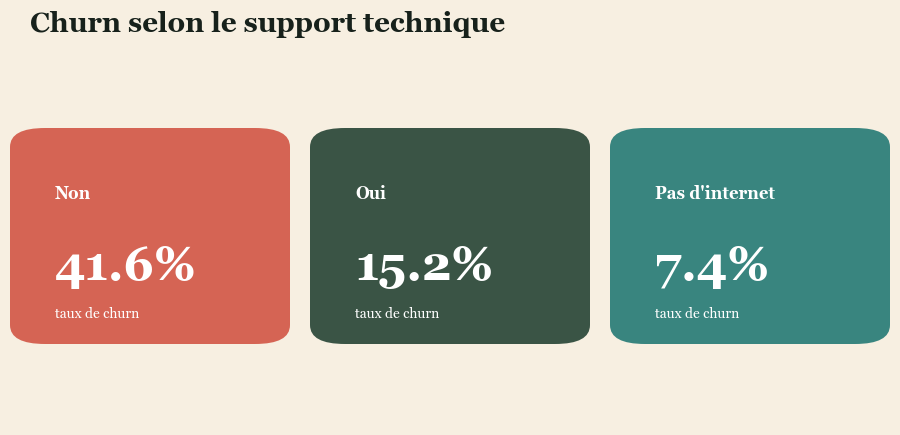

In [27]:
rates_support = df.groupby("TechSupport")["ChurnBinary"].mean().mul(100).sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(10, 5.4))
ax.axis("off")
fig.text(0.08, 0.84, "Churn selon le support technique", fontsize=20, fontweight="bold", color=INK)
xs = [0.08, 0.38, 0.68]
card_colors = [CORAL, MOSS, TEAL]
for idx, row in rates_support.reset_index(drop=True).iterrows():
    x0 = xs[idx]
    rect = mpl.patches.FancyBboxPatch((x0, 0.28), 0.24, 0.36, boxstyle="round,pad=0.02,rounding_size=0.035", transform=fig.transFigure, facecolor=card_colors[idx], edgecolor="none", alpha=0.95)
    fig.add_artist(rect)
    fig.text(x0 + 0.025, 0.53, label_category(row["TechSupport"]), fontsize=12, color="white", fontweight="bold")
    fig.text(x0 + 0.025, 0.38, f"{row['ChurnBinary']:.1f}%", fontsize=34, color="white", fontweight="bold")
    fig.text(x0 + 0.025, 0.31, "taux de churn", fontsize=10, color="white")
plt.show()
save(fig, "churn_by_tech_support.png")

### Churn selon l anciennete

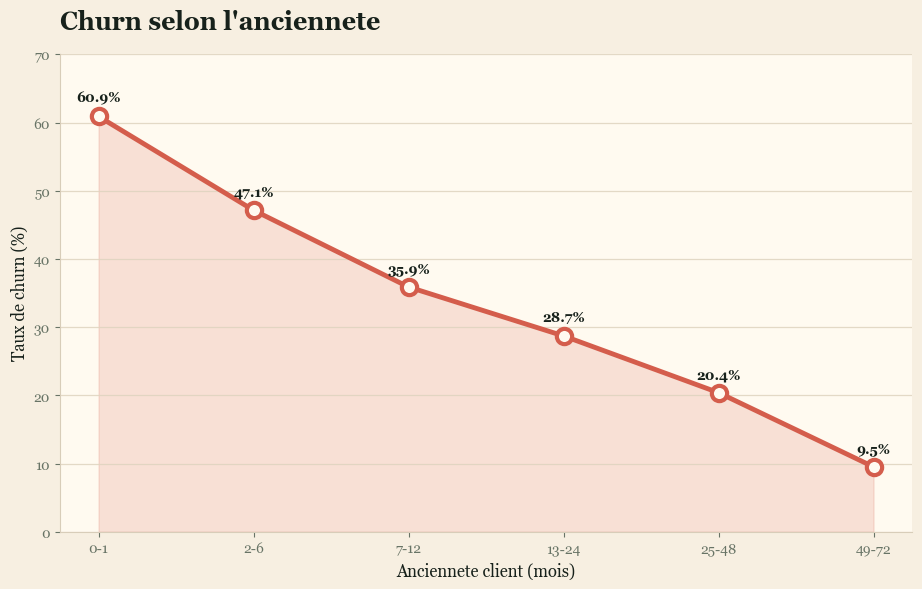

In [28]:
bins = [0, 1, 6, 12, 24, 48, 72]
labels = ["0-1", "2-6", "7-12", "13-24", "25-48", "49-72"]
df["tenure_bucket"] = pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True)
rates_tenure = df.groupby("tenure_bucket", observed=False)["ChurnBinary"].mean().mul(100).reset_index()

fig, ax = plt.subplots(figsize=(11, 6.2))
x = np.arange(len(rates_tenure))
ax.plot(x, rates_tenure["ChurnBinary"], color=CORAL, linewidth=3.5, marker="o", markersize=11, markerfacecolor=PANEL, markeredgewidth=3)
ax.fill_between(x, rates_tenure["ChurnBinary"], color=CORAL, alpha=0.16)
for xi, value in zip(x, rates_tenure["ChurnBinary"]):
    ax.text(xi, value + 2.1, f"{value:.1f}%", ha="center", fontweight="bold", color=INK)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 70)
ax.set_xlabel("Anciennete client (mois)")
ax.set_ylabel("Taux de churn (%)")
ax.set_title("Churn selon l'anciennete", loc="left", pad=18)
polish(ax)
plt.show()
save(fig, "churn_by_tenure.png")

### Distribution des charges mensuelles selon le churn

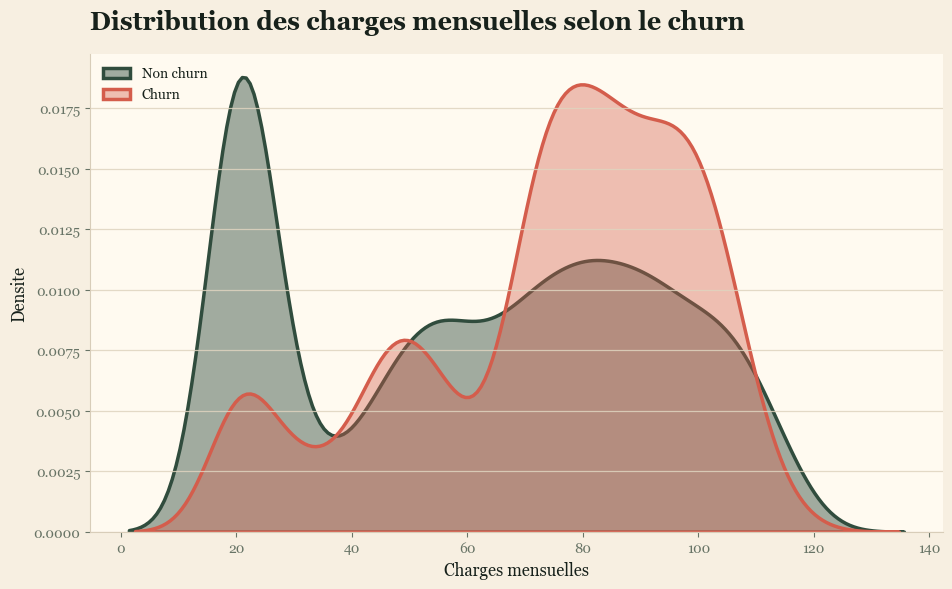

In [29]:
fig, ax = plt.subplots(figsize=(11, 6.2))
sns.kdeplot(data=df[df["Churn"] == "No"], x="MonthlyCharges", fill=True, alpha=0.45, color=MOSS, linewidth=2.5, ax=ax, label="Non churn")
sns.kdeplot(data=df[df["Churn"] == "Yes"], x="MonthlyCharges", fill=True, alpha=0.38, color=CORAL, linewidth=2.5, ax=ax, label="Churn")
ax.set_title("Distribution des charges mensuelles selon le churn", loc="left", pad=18)
ax.set_xlabel("Charges mensuelles")
ax.set_ylabel("Densite")
ax.legend(frameon=False, loc="upper left")
polish(ax)
plt.show()
save(fig, "monthly_charges_distribution.png")

## Vue d ensemble analytique

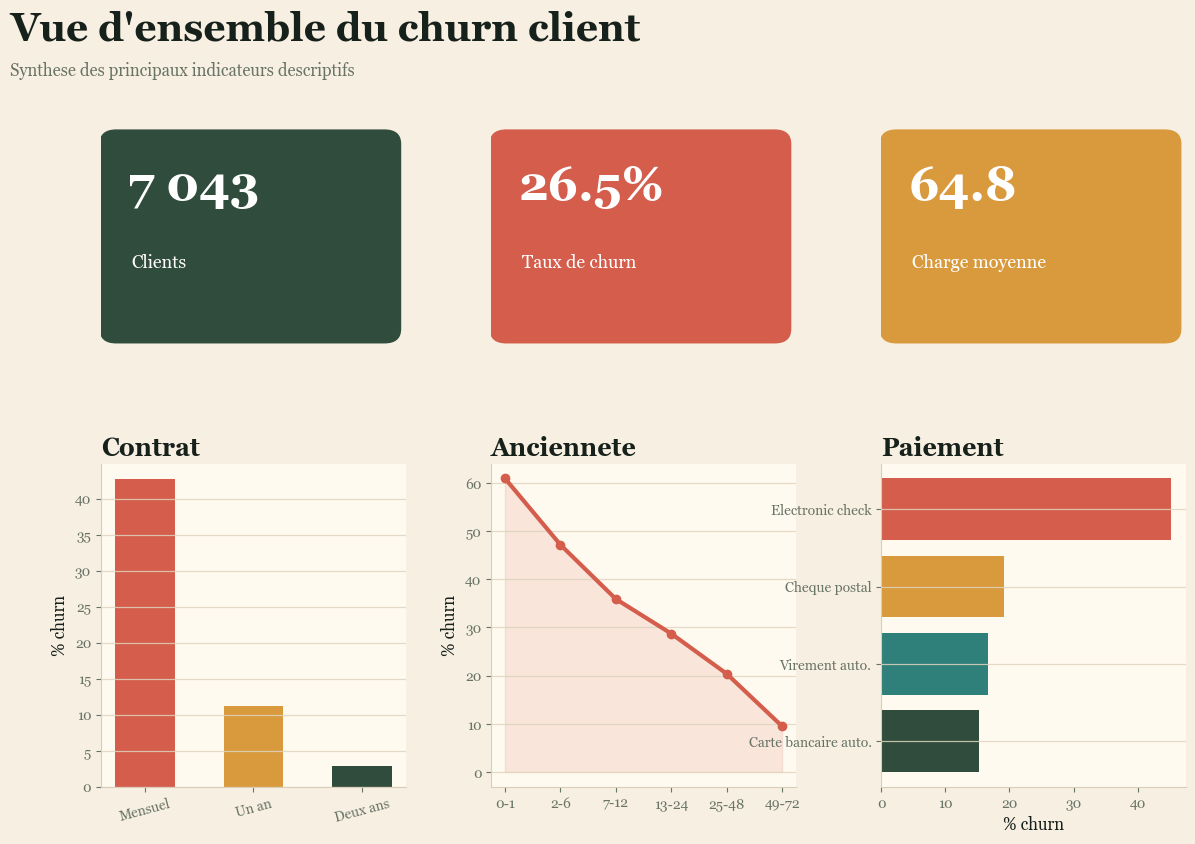

In [30]:
fig = plt.figure(figsize=(14, 9), facecolor=BG)
gs = fig.add_gridspec(2, 3, height_ratios=[0.9, 1.1], hspace=0.36, wspace=0.28)
fig.text(0.06, 0.94, "Vue d'ensemble du churn client", fontsize=28, fontweight="bold", color=INK)
fig.text(0.06, 0.90, "Synthese des principaux indicateurs descriptifs", fontsize=12, color=MUTED)

kpis = [
    ("Clients", f"{len(df):,}".replace(",", " "), MOSS),
    ("Taux de churn", f"{df['ChurnBinary'].mean() * 100:.1f}%", CORAL),
    ("Charge moyenne", f"{df['MonthlyCharges'].mean():.1f}", AMBER),
]

for i, (label, value, color) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.axis("off")
    ax.add_patch(mpl.patches.FancyBboxPatch((0.02, 0.08), 0.94, 0.76, boxstyle="round,pad=0.025,rounding_size=0.055", transform=ax.transAxes, facecolor=color, edgecolor="none"))
    ax.text(0.09, 0.60, value, transform=ax.transAxes, fontsize=34, fontweight="bold", color="white")
    ax.text(0.10, 0.34, label, transform=ax.transAxes, fontsize=13, color="white")

ax1 = fig.add_subplot(gs[1, 0])
contract = df.groupby("Contract")["ChurnBinary"].mean().mul(100).reindex(order)
ax1.bar([label_category(v) for v in contract.index], contract.values, color=[CORAL, AMBER, MOSS], width=0.55)
ax1.set_title("Contrat", loc="left")
ax1.set_ylabel("% churn")
ax1.tick_params(axis="x", rotation=15)
polish(ax1)

ax2 = fig.add_subplot(gs[1, 1])
ax2.plot(x, rates_tenure["ChurnBinary"], color=CORAL, linewidth=3, marker="o")
ax2.fill_between(x, rates_tenure["ChurnBinary"], color=CORAL, alpha=0.13)
ax2.set_xticks(x)
ax2.set_xticklabels(labels)
ax2.set_title("Anciennete", loc="left")
ax2.set_ylabel("% churn")
polish(ax2)

ax3 = fig.add_subplot(gs[1, 2])
rates_payment_sorted = rates_payment.sort_values("ChurnBinary")
ax3.barh([label_category(v) for v in rates_payment_sorted["PaymentMethod"]], rates_payment_sorted["ChurnBinary"], color=[MOSS, TEAL, AMBER, CORAL])
ax3.set_title("Paiement", loc="left")
ax3.set_xlabel("% churn")
polish(ax3)

plt.show()
save(fig, "churn_dashboard_overview.png")